# 02 — RAG Uncertainty Eval: Dataset Construction (English)

**Research goal:** Evaluate whether RAG agents know when they *don't know* by presenting topically-related but answer-free passages (distractors) and measuring hallucination / abstention / hedging.

**This notebook:**
1. Loads MIRACL hard-negatives for English
2. Builds a flat evaluation table: one row per `(query, distractor_passage)` pair
3. Adds a difficulty score (TF-IDF cosine similarity: distractor ↔ gold passage)
4. Saves two artefacts to `../data/`:
   - `rag_eval_en_full.csv` — all query×negative pairs (used for ablation)
   - `rag_eval_en_300.csv` — stratified 300-row sample (one per query, spread across difficulty tiers)
5. EDA of the constructed dataset

In [4]:
# !pip install -q datasets pandas scikit-learn matplotlib seaborn

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)

DATASET   = "datalama/miracl-hard-negatives"
LANG      = "en"
SEED      = 42
N_SAMPLE  = 300

## 1  Load English split

In [6]:
corpus_en  = load_dataset(DATASET, f"corpus-{LANG}",  split="corpus").to_pandas()
queries_en = load_dataset(DATASET, f"queries-{LANG}", split="queries").to_pandas()
qrels_en   = load_dataset(DATASET, LANG,              split="dev").to_pandas()

corpus_en  = corpus_en.rename(columns={"_id": "corpus_id"})
queries_en = queries_en.rename(columns={"_id": "query_id", "text": "query"})
qrels_en   = qrels_en.rename(columns={"query-id": "query_id", "corpus-id": "corpus_id"})

print(f"Corpus:  {len(corpus_en):>7,} passages")
print(f"Queries: {len(queries_en):>7,}")
print(f"Qrels:   {len(qrels_en):>7,} pairs  (score=1 positive, score=0 hard-negative)")

Corpus:  178,768 passages
Queries:     799
Qrels:     8,350 pairs  (score=1 positive, score=0 hard-negative)


## 2  Build the evaluation table

For each query we collect:
- **Gold passage** — the first annotated positive (title used as *answer proxy*)
- **Distractor passages** — all annotated hard negatives (score = 0)

One row = one `(query, distractor)` pair.

In [7]:
# Attach passage text+title to qrels
qrels_joined = qrels_en.merge(corpus_en, on="corpus_id", how="left")
qrels_joined = qrels_joined.merge(queries_en, on="query_id", how="left")

positives = qrels_joined[qrels_joined["score"] == 1].copy()
negatives = qrels_joined[qrels_joined["score"] == 0].copy()

print(f"Positive qrels: {len(positives):,}")
print(f"Negative qrels: {len(negatives):,}")

Positive qrels: 2,326
Negative qrels: 6,024


In [8]:
# One gold passage per query (first positive, deterministic)
gold = (
    positives
    .sort_values(["query_id", "corpus_id"])
    .groupby("query_id", as_index=False)
    .first()[["query_id", "corpus_id", "text", "title"]]
    .rename(columns={"corpus_id": "gold_passage_id",
                     "text":      "gold_passage_text",
                     "title":     "gold_passage_title"})
)
gold["gold_answer"] = gold["gold_passage_title"]   # title as answer proxy

# Count positives / negatives per query
n_pos = positives.groupby("query_id").size().rename("n_positives")
n_neg = negatives.groupby("query_id").size().rename("n_negatives")

gold = gold.merge(n_pos, on="query_id").merge(n_neg, on="query_id")

print(f"Queries with at least one positive: {len(gold):,}")

Queries with at least one positive: 787


In [9]:
# Enumerate negatives per query (neg_rank: 0 = first retrieved)
negatives = negatives.sort_values(["query_id", "corpus_id"]).copy()
negatives["neg_rank"] = negatives.groupby("query_id").cumcount()

# Keep only queries that have a gold passage
negatives = negatives[negatives["query_id"].isin(gold["query_id"])]

# Merge gold info onto each distractor row
df = negatives.rename(columns={"corpus_id": "distractor_id",
                                "text":      "distractor_text",
                                "title":     "distractor_title"}).merge(
    gold, on="query_id", how="left"
)

df = df[["query_id", "query",
         "distractor_id", "distractor_text", "distractor_title",
         "gold_passage_id", "gold_passage_text", "gold_passage_title", "gold_answer",
         "n_positives", "n_negatives", "neg_rank"]].reset_index(drop=True)

print(f"Full eval table: {len(df):,} rows  ({df['query_id'].nunique():,} unique queries)")
df.head(3)

Full eval table: 6,024 rows  (787 unique queries)


,query_id,query,distractor_id,distractor_text,distractor_title,gold_passage_id,gold_passage_text,gold_passage_title,gold_answer,n_positives,n_negatives,neg_rank
0,0,Is Creole a pidgin of French?,11236157#2,"While many creoles around the world have lexicons based on languages other than Portuguese (e.g. English, French, Sp...",Monogenetic theory of pidgins,22399755#18,There are many hypotheses on the origins of Haitian Creole. Linguist John Singler suggests that it most likely emerg...,Haitian literature,Haitian literature,4,8,0
1,0,Is Creole a pidgin of French?,1170520#2,Louisiana Creole is a contact language that arose in the 18th century from interactions between speakers of the lexi...,Louisiana Creole,22399755#18,There are many hypotheses on the origins of Haitian Creole. Linguist John Singler suggests that it most likely emerg...,Haitian literature,Haitian literature,4,8,1
2,0,Is Creole a pidgin of French?,1612877#8,"A mixed language differs from pidgins, creoles and code-switching in very fundamental ways. In most cases, mixed lan...",Mixed language,22399755#18,There are many hypotheses on the origins of Haitian Creole. Linguist John Singler suggests that it most likely emerg...,Haitian literature,Haitian literature,4,8,2


## 3  Difficulty score: TF-IDF cosine similarity (distractor ↔ gold passage)

Higher similarity → the distractor is *topically closer* to the gold passage → harder distractor.  
This is used for the ablation analysis in Step 5 of the research plan.

In [10]:
df["distractor_text"]  = df["distractor_text"].fillna("")
df["gold_passage_text"] = df["gold_passage_text"].fillna("")

print("Fitting TF-IDF vectoriser on all passage texts …")
all_texts = pd.concat([df["distractor_text"], df["gold_passage_text"]]).unique()
vectoriser = TfidfVectorizer(max_features=30_000, sublinear_tf=True, ngram_range=(1, 2))
vectoriser.fit(all_texts)

dist_vecs = vectoriser.transform(df["distractor_text"])
gold_vecs = vectoriser.transform(df["gold_passage_text"])

# Row-wise cosine similarity
sims = np.array(dist_vecs.multiply(gold_vecs).sum(axis=1)).flatten()
norms_d = np.sqrt(np.array(dist_vecs.power(2).sum(axis=1)).flatten())
norms_g = np.sqrt(np.array(gold_vecs.power(2).sum(axis=1)).flatten())
denom = norms_d * norms_g
df["tfidf_sim"] = np.where(denom > 0, sims / denom, 0.0).round(4)

# Difficulty bin (tertiles across the full dataset)
q33, q67 = df["tfidf_sim"].quantile([0.33, 0.67])
df["difficulty"] = pd.cut(
    df["tfidf_sim"],
    bins=[-np.inf, q33, q67, np.inf],
    labels=["easy", "medium", "hard"]
)

print(f"TF-IDF sim  — mean: {df['tfidf_sim'].mean():.4f}  "
      f"median: {df['tfidf_sim'].median():.4f}  "
      f"max: {df['tfidf_sim'].max():.4f}")
print(f"Tertile thresholds: easy < {q33:.4f} ≤ medium < {q67:.4f} ≤ hard")
print(df["difficulty"].value_counts())

Fitting TF-IDF vectoriser on all passage texts …
TF-IDF sim  — mean: 0.1516  median: 0.1431  max: 0.8912
Tertile thresholds: easy < 0.1040 ≤ medium < 0.1838 ≤ hard
difficulty
medium    2049
easy      1988
hard      1987
Name: count, dtype: int64


## 4  Text-length features

In [11]:
df["query_len"]      = df["query"].str.len()
df["distractor_len"] = df["distractor_text"].str.len()
df["gold_len"]       = df["gold_passage_text"].str.len()

df[["query_len", "distractor_len", "gold_len"]].describe().round(1)

,query_len,distractor_len,gold_len
count,6024.0,6024.0,6024.0
mean,40.2,646.7,672.0
std,13.0,467.9,400.6
min,16.0,0.0,51.0
25%,31.0,359.0,415.0
50%,38.0,616.5,592.0
75%,48.0,887.0,815.0
max,122.0,5851.0,3180.0


## 5  Stratified 300-row sample

Strategy: one distractor per query, stratified across difficulty tiers (100 easy / 100 medium / 100 hard).  
Within each tier, pick the query's *hardest* available distractor (highest `tfidf_sim`) to maximise challenge.

In [12]:
# For each (query, difficulty tier), keep the hardest distractor
df_hardest = (
    df.sort_values("tfidf_sim", ascending=False)
      .groupby(["query_id", "difficulty"], as_index=False)
      .first()
)

per_tier = N_SAMPLE // 3   # 100
sampled_parts = []
for tier in ["easy", "medium", "hard"]:
    pool = df_hardest[df_hardest["difficulty"] == tier]
    n    = min(per_tier, len(pool))
    sampled_parts.append(pool.sample(n=n, random_state=SEED))
    print(f"  {tier:6s}: {len(pool):3d} available → sampled {n}")

df_300 = pd.concat(sampled_parts).reset_index(drop=True)
print(f"\nFinal 300-row sample: {len(df_300)} rows")
df_300["difficulty"].value_counts()

  easy  : 521 available → sampled 100
  medium: 651 available → sampled 100
  hard  : 579 available → sampled 100

Final 300-row sample: 300 rows


difficulty
easy      100
medium    100
hard      100
Name: count, dtype: int64

## 6  Save to CSV

In [13]:
full_path   = DATA_DIR / "rag_eval_en_full.csv"
sample_path = DATA_DIR / "rag_eval_en_300.csv"

df.to_csv(full_path,   index=False)
df_300.to_csv(sample_path, index=False)

print(f"Saved full dataset  → {full_path}   ({len(df):,} rows)")
print(f"Saved 300 sample    → {sample_path}  ({len(df_300)} rows)")
print(f"\nColumns: {list(df.columns)}")

Saved full dataset  → ../data/rag_eval_en_full.csv   (6,024 rows)
Saved 300 sample    → ../data/rag_eval_en_300.csv  (300 rows)

Columns: ['query_id', 'query', 'distractor_id', 'distractor_text', 'distractor_title', 'gold_passage_id', 'gold_passage_text', 'gold_passage_title', 'gold_answer', 'n_positives', 'n_negatives', 'neg_rank', 'tfidf_sim', 'difficulty', 'query_len', 'distractor_len', 'gold_len']


---
## 7  EDA — Full dataset (`rag_eval_en_full`)

### 7.1  Basic counts

In [14]:
print("=== Full dataset ===")
print(f"Rows (query × distractor pairs): {len(df):,}")
print(f"Unique queries:                  {df['query_id'].nunique():,}")
print(f"Unique distractor passages:      {df['distractor_id'].nunique():,}")
print()
print(df[["n_positives", "n_negatives", "tfidf_sim",
          "query_len", "distractor_len", "gold_len"]].describe().round(2))

=== Full dataset ===
Rows (query × distractor pairs): 6,024
Unique queries:                  787
Unique distractor passages:      5,673

       n_positives  n_negatives  tfidf_sim  query_len  distractor_len  \
count      6024.00      6024.00    6024.00    6024.00         6024.00   
mean          2.36         8.14       0.15      40.25          646.74   
std           1.55         1.62       0.11      12.95          467.92   
min           1.00         1.00       0.00      16.00            0.00   
25%           1.00         7.00       0.08      31.00          359.00   
50%           2.00         8.00       0.14      38.00          616.50   
75%           3.00         9.00       0.21      48.00          887.00   
max          12.00        14.00       0.89     122.00         5851.00   

       gold_len  
count   6024.00  
mean     671.99  
std      400.59  
min       51.00  
25%      415.00  
50%      592.00  
75%      815.00  
max     3180.00  


### 7.2  Negatives-per-query distribution

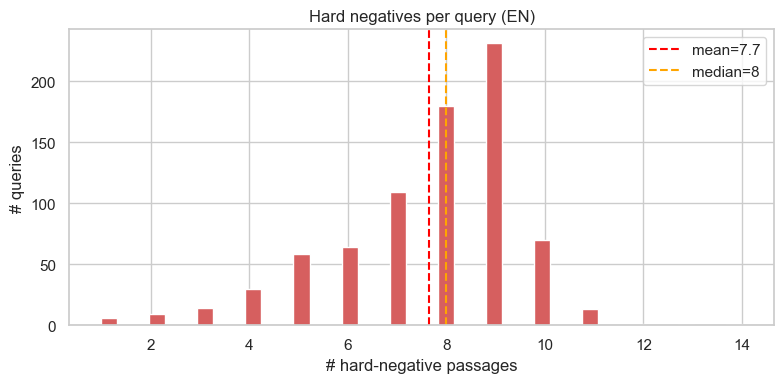

count    787.000000
mean       7.654384
std        1.935996
min        1.000000
25%        7.000000
50%        8.000000
75%        9.000000
max       14.000000
Name: n_negatives, dtype: float64


In [15]:
neg_counts = df.groupby("query_id")["n_negatives"].first()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(neg_counts, bins=40, color=sns.color_palette("muted")[3], edgecolor="white")
ax.axvline(neg_counts.mean(),   color="red",    linestyle="--", linewidth=1.5, label=f"mean={neg_counts.mean():.1f}")
ax.axvline(neg_counts.median(), color="orange", linestyle="--", linewidth=1.5, label=f"median={neg_counts.median():.0f}")
ax.set_title("Hard negatives per query (EN)")
ax.set_xlabel("# hard-negative passages")
ax.set_ylabel("# queries")
ax.legend()
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_negatives_per_query.png", dpi=120)
plt.show()
print(neg_counts.describe())

### 7.3  Distractor difficulty (TF-IDF similarity) distribution

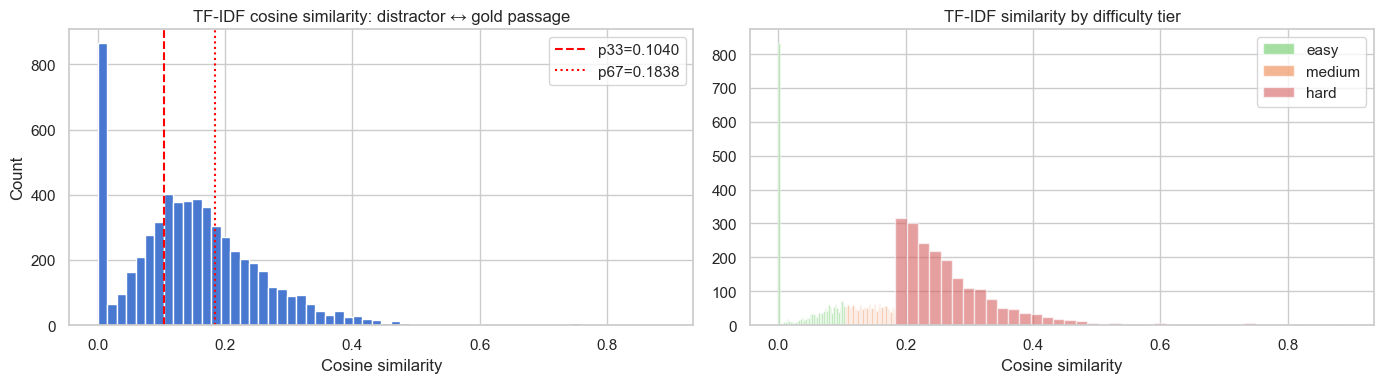

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram
axes[0].hist(df["tfidf_sim"], bins=60, color=sns.color_palette("muted")[0], edgecolor="white")
for q, ls in [(0.33, "--"), (0.67, ":")]:
    val = df["tfidf_sim"].quantile(q)
    axes[0].axvline(val, color="red", linestyle=ls, linewidth=1.5, label=f"p{int(q*100)}={val:.4f}")
axes[0].set_title("TF-IDF cosine similarity: distractor ↔ gold passage")
axes[0].set_xlabel("Cosine similarity")
axes[0].set_ylabel("Count")
axes[0].legend()

# By difficulty tier
palette = {"easy": sns.color_palette("muted")[2],
           "medium": sns.color_palette("muted")[1],
           "hard": sns.color_palette("muted")[3]}
for tier, color in palette.items():
    subset = df[df["difficulty"] == tier]["tfidf_sim"]
    axes[1].hist(subset, bins=40, alpha=0.6, color=color, edgecolor="white", label=tier)
axes[1].set_title("TF-IDF similarity by difficulty tier")
axes[1].set_xlabel("Cosine similarity")
axes[1].legend()

plt.tight_layout()
plt.savefig(DATA_DIR / "fig_tfidf_similarity.png", dpi=120)
plt.show()

### 7.4  Text length distributions

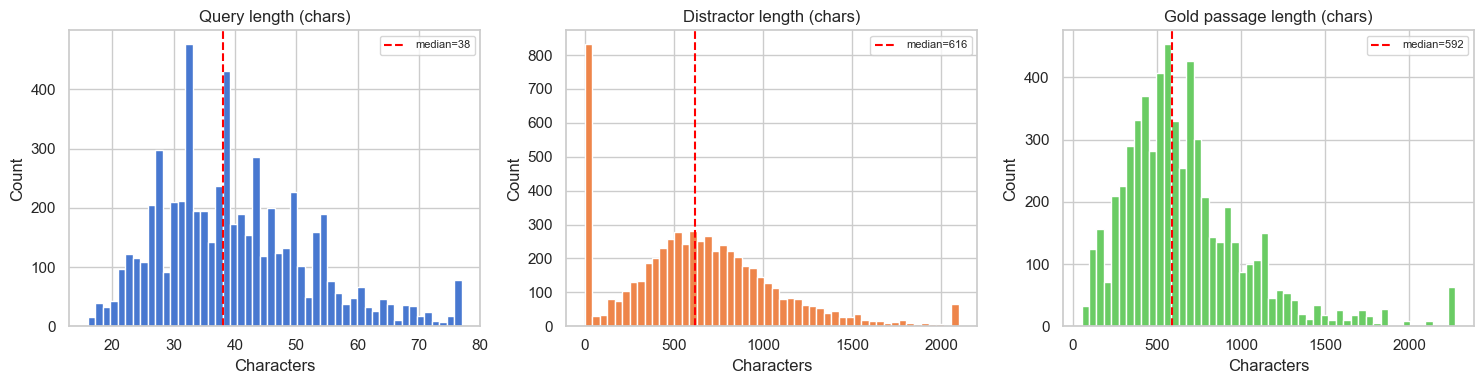

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cols   = ["query_len", "distractor_len", "gold_len"]
labels = ["Query length (chars)", "Distractor length (chars)", "Gold passage length (chars)"]
colors = sns.color_palette("muted")

for ax, col, label, color in zip(axes, cols, labels, colors):
    clip = df[col].clip(upper=df[col].quantile(0.99))
    ax.hist(clip, bins=50, color=color, edgecolor="white")
    ax.axvline(df[col].median(), color="red", linestyle="--", linewidth=1.5,
               label=f"median={df[col].median():.0f}")
    ax.set_title(label)
    ax.set_xlabel("Characters")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(DATA_DIR / "fig_text_lengths.png", dpi=120)
plt.show()

### 7.5  Difficulty tier vs. passage lengths

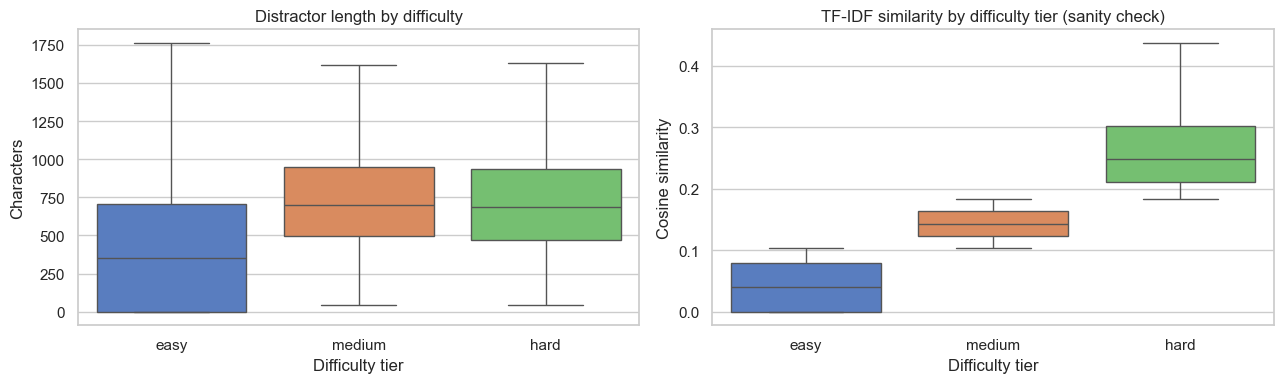

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

order = ["easy", "medium", "hard"]

sns.boxplot(data=df, x="difficulty", y="distractor_len", order=order,
            palette="muted", ax=axes[0], showfliers=False)
axes[0].set_title("Distractor length by difficulty")
axes[0].set_xlabel("Difficulty tier")
axes[0].set_ylabel("Characters")

sns.boxplot(data=df, x="difficulty", y="tfidf_sim", order=order,
            palette="muted", ax=axes[1], showfliers=False)
axes[1].set_title("TF-IDF similarity by difficulty tier (sanity check)")
axes[1].set_xlabel("Difficulty tier")
axes[1].set_ylabel("Cosine similarity")

plt.tight_layout()
plt.savefig(DATA_DIR / "fig_difficulty_vs_length.png", dpi=120)
plt.show()

### 7.6  Neg-rank distribution (position of distractor in the negative list)

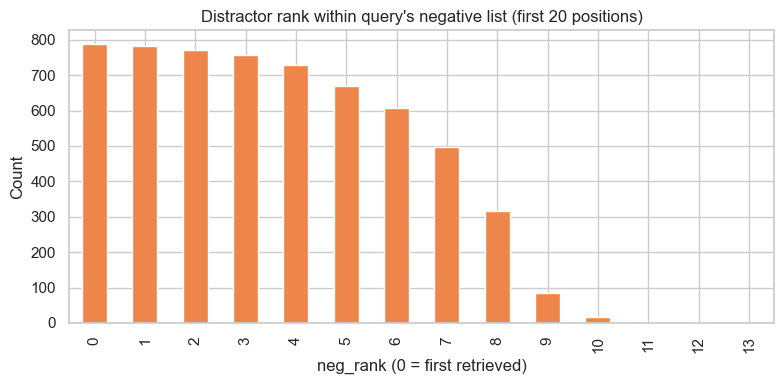

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
df["neg_rank"].value_counts().sort_index().head(20).plot(
    kind="bar", ax=ax, color=sns.color_palette("muted")[1], edgecolor="white"
)
ax.set_title("Distractor rank within query's negative list (first 20 positions)")
ax.set_xlabel("neg_rank (0 = first retrieved)")
ax.set_ylabel("Count")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_neg_rank.png", dpi=120)
plt.show()

### 7.7  300-row sample — difficulty breakdown and similarity profile

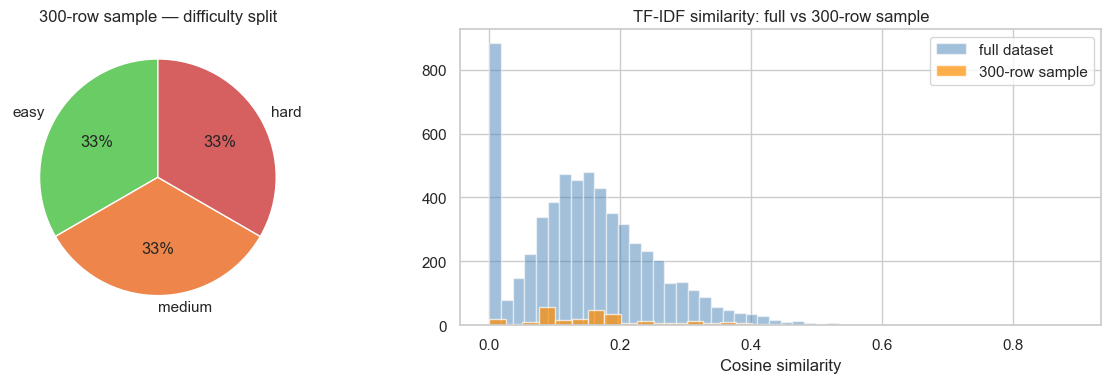

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Pie chart of difficulty tiers
tier_counts = df_300["difficulty"].value_counts()[order]
axes[0].pie(tier_counts, labels=tier_counts.index, autopct="%1.0f%%",
            colors=[palette[t] for t in tier_counts.index], startangle=90)
axes[0].set_title(f"300-row sample — difficulty split")

# TF-IDF sim distribution in sample vs full
axes[1].hist(df["tfidf_sim"],     bins=50, alpha=0.5, color="steelblue",  edgecolor="white", label="full dataset")
axes[1].hist(df_300["tfidf_sim"], bins=30, alpha=0.7, color="darkorange", edgecolor="white", label="300-row sample")
axes[1].set_title("TF-IDF similarity: full vs 300-row sample")
axes[1].set_xlabel("Cosine similarity")
axes[1].legend()

plt.tight_layout()
plt.savefig(DATA_DIR / "fig_sample_profile.png", dpi=120)
plt.show()

### 7.8  Qualitative examples — one from each difficulty tier

In [21]:
for tier in ["easy", "medium", "hard"]:
    row = df_300[df_300["difficulty"] == tier].sample(1, random_state=SEED).iloc[0]
    print(f"\n{'='*80}")
    print(f"DIFFICULTY: {tier.upper()}  |  TF-IDF sim = {row['tfidf_sim']:.4f}")
    print(f"QUERY:      {row['query']}")
    print(f"GOLD TITLE: {row['gold_passage_title']}")
    print(f"GOLD PASS:  {row['gold_passage_text'][:300]}…")
    print(f"DISTRACTOR: {row['distractor_text'][:300]}…")
    print(f"GOLD ANSWER (proxy): {row['gold_answer']}")


DIFFICULTY: EASY  |  TF-IDF sim = 0.0819
QUERY:      When did the slaves in South Africa gain their freedom?
GOLD TITLE: Slavery in South Africa
GOLD PASS:  Slavery in South Africa existed until the abolition of slavery in 1834.…
DISTRACTOR: After General Benjamin Butler decided to treat slaves flocking to his Union lines as contraband of war, plantation owners began moving their slaves far away from Union armies. Some planters moved south to Brazil during the war, including Arkansans. Congress passed the Confiscation Act of 1862 that s…
GOLD ANSWER (proxy): Slavery in South Africa

DIFFICULTY: MEDIUM  |  TF-IDF sim = 0.1588
QUERY:      How long is Northern Boulevard in Albany, NY?
GOLD TITLE: Streets of Albany, New York
GOLD PASS:  Swallow Street (whose name was Gage prior to 1790) was one of the few bird streets whose name was not kept, its name being changed to Knox Street in 1809. Knox Street would stretch north from Myrtle Avenue to Clinton Avenue, and eventually to Livingston Av

### 7.9  Correlation: distractor length vs similarity

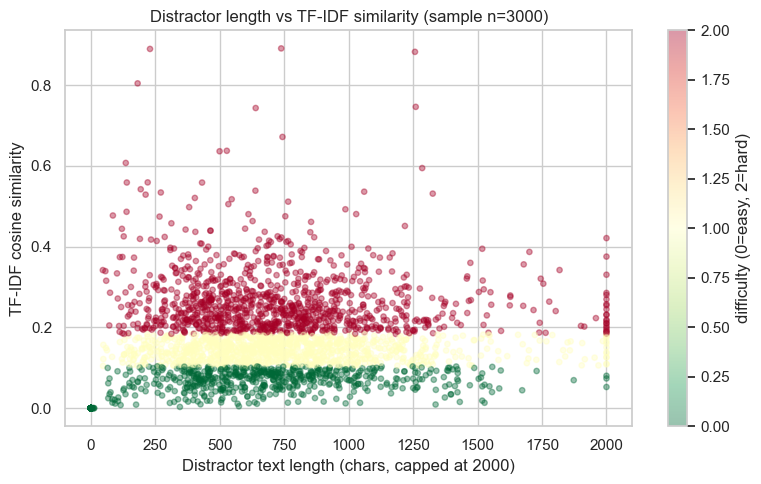

Pearson r (distractor_len vs tfidf_sim): 0.314


In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
sample = df.sample(min(3000, len(df)), random_state=SEED)
scatter = ax.scatter(
    sample["distractor_len"].clip(upper=2000),
    sample["tfidf_sim"],
    c=sample["difficulty"].map({"easy": 0, "medium": 1, "hard": 2}),
    cmap="RdYlGn_r", alpha=0.4, s=15
)
plt.colorbar(scatter, label="difficulty (0=easy, 2=hard)")
ax.set_title("Distractor length vs TF-IDF similarity (sample n=3000)")
ax.set_xlabel("Distractor text length (chars, capped at 2000)")
ax.set_ylabel("TF-IDF cosine similarity")
plt.tight_layout()
plt.savefig(DATA_DIR / "fig_scatter_len_vs_sim.png", dpi=120)
plt.show()

r = df[["distractor_len", "tfidf_sim"]].corr().iloc[0, 1]
print(f"Pearson r (distractor_len vs tfidf_sim): {r:.3f}")

## 8  Summary

In [23]:
print("=" * 55)
print("RAG Uncertainty Eval — Dataset Construction Summary")
print("=" * 55)
print(f"Source dataset:       {DATASET}  (EN split)")
print(f"Unique queries:       {df['query_id'].nunique():,}")
print(f"Total distractor rows:{len(df):,}")
print(f"Avg distractors/query:{df['n_negatives'].mean():.1f}")
print()
print("Full dataset saved to:", full_path)
print("300-row sample to:    ", sample_path)
print()
print("Difficulty breakdown (full):")
print(df["difficulty"].value_counts().to_string())
print()
print("300-row sample breakdown:")
print(df_300["difficulty"].value_counts().to_string())
print()
print("Columns in output CSVs:")
for col in df.columns:
    print(f"  {col}")

RAG Uncertainty Eval — Dataset Construction Summary
Source dataset:       datalama/miracl-hard-negatives  (EN split)
Unique queries:       787
Total distractor rows:6,024
Avg distractors/query:8.1

Full dataset saved to: ../data/rag_eval_en_full.csv
300-row sample to:     ../data/rag_eval_en_300.csv

Difficulty breakdown (full):
difficulty
medium    2049
easy      1988
hard      1987

300-row sample breakdown:
difficulty
easy      100
medium    100
hard      100

Columns in output CSVs:
  query_id
  query
  distractor_id
  distractor_text
  distractor_title
  gold_passage_id
  gold_passage_text
  gold_passage_title
  gold_answer
  n_positives
  n_negatives
  neg_rank
  tfidf_sim
  difficulty
  query_len
  distractor_len
  gold_len
